In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU")

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
import sys
import spacy
import importlib
from pathlib import Path

try:
    import en_core_sci_sm

except ImportError:

    print("Installing SciSpaCy en_core_sci_sm...")

    !{sys.executable} -m pip install -q --no-deps https://s3-us-west-2.amazonaws.com/ai2-s2-scispacy/releases/v0.5.4/en_core_sci_sm-0.5.4.tar.gz

    importlib.invalidate_caches()

    import en_core_sci_sm


# Patch model configuration
try:

    package_dir = Path(en_core_sci_sm.__file__).parent

    patched_count = 0

    for config_path in package_dir.rglob("config.cfg"):

        config_text = config_path.read_text()

        config_text = config_text.replace(
            'include_static_vectors = "False"',
            'include_static_vectors = false'
        )

        config_text = config_text.replace(
            "include_static_vectors = 'False'",
            "include_static_vectors = false"
        )

        config_text = config_text.replace(
            "include_static_vectors = False",
            "include_static_vectors = false"
        )

        config_path.write_text(config_text)

        patched_count += 1

    print("Patched config files:", patched_count)

except Exception as error:

    print("Configuration patch warning:", error)


# Load SciSpaCy
sci_model = spacy.load("en_core_sci_sm")

print("SciSpaCy model loaded successfully!")
print("spaCy version:", spacy.__version__)

Installing SciSpaCy en_core_sci_sm...
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


/usr/local/lib/python3.13/dist-packages/spacy/util.py:971: UserWarning: [W095] Model 'en_core_sci_sm' (0.5.4) was trained with spaCy v3.7.4 and may not be 100% compatible with the current version (3.8.18). If you see errors or degraded performance, download a newer compatible model or retrain your custom model with the current spaCy version. For more details and available updates, run: python -m spacy validate
  warnings.warn(warn_msg)


Patched config files: 1


/usr/local/lib/python3.13/dist-packages/spacy/language.py:2235: FutureWarning: Possible set union at position 6328
  deserializers["tokenizer"] = lambda p: self.tokenizer.from_disk(  # type: ignore[union-attr]


SciSpaCy model loaded successfully!
spaCy version: 3.8.18


In [ ]:
import os
import re
import json
import shutil
import warnings

from pathlib import Path
from collections import Counter

import torch
import spacy
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from transformers import pipeline
from IPython.display import display

warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
import os

REPO_URL = (
    "https://github.com/jche253/"
    "Glaucoma_Med_Dataset.git"
)

REPO_FOLDER = Path(
    "/content/Glaucoma_Med_Dataset"
)

if REPO_FOLDER.exists():

    print("Dataset repository already exists.")

else:

    !git clone https://github.com/jche253/Glaucoma_Med_Dataset.git

print("\nDataset cloned successfully!")
print("Repository:", REPO_FOLDER)

Cloning into 'Glaucoma_Med_Dataset'...
remote: Enumerating objects: 527, done.
remote: Counting objects: 100% (527/527), done.
remote: Compressing objects: 100% (519/519), done.
remote: Total 527 (delta 20), reused 487 (delta 8), pack-reused 0 (from 0)
Receiving objects: 100% (527/527), 1.08 MiB | 2.89 MiB/s, done.
Resolving deltas: 100% (20/20), done.

Dataset cloned successfully!
Repository: /content/Glaucoma_Med_Dataset


Folder Structure Validation

In [ ]:
NOTES_FOLDER = REPO_FOLDER / "Deidentified_Notes"

ANNOTATIONS_FOLDER = REPO_FOLDER / "Annotations"

print("Notes folder exists:", NOTES_FOLDER.exists())
print("Annotations folder exists:", ANNOTATIONS_FOLDER.exists())

if not NOTES_FOLDER.exists():
    raise FileNotFoundError(
        "Deidentified_Notes folder not found!"
    )

note_files = sorted(
    NOTES_FOLDER.rglob("*.txt")
)

print("\nTotal clinical notes:", len(note_files))

print("\nFirst 10 clinical notes:")

for file in note_files[:10]:
    print(file.name)

print("\nAnnotation files:")

if ANNOTATIONS_FOLDER.exists():

    for file in ANNOTATIONS_FOLDER.rglob("*"):
        if file.is_file():
            print(file.relative_to(REPO_FOLDER))

Notes folder exists: True
Annotations folder exists: True

Total clinical notes: 480

First 10 clinical notes:
01655bde5b.txt
01dcccc1a1.txt
0217483bd3.txt
025920c6c9.txt
0333bead9c.txt
04bd960ee3.txt
04f61bdb82.txt
0576b0da32.txt
058de1cfe4.txt
058fdc04d7.txt

Annotation files:
Annotations/Combined_annotations.jsonl
Annotations/Combined_annotations.txt


Sample Text Inspection

In [ ]:
if len(note_files) == 0:
    raise FileNotFoundError("No TXT notes found!")

first_file = note_files[0]

with open(
    first_file,
    "r",
    encoding="utf-8",
    errors="ignore"
) as f:

    sample_text = f.read()

print("Patient ID:", first_file.stem)

print("\nClinical Note:")
print("=" * 70)

print(sample_text[:3000])

print("\nTotal characters:", len(sample_text))

Patient ID: 01655bde5b

Clinical Note:
   ***** *** ********* Progress Note */**/****  CC: Annual health maintenance examination    Diabetic Eye Examination   Pt here for annual diabetic eye exam ( pt is ***)   - OD is getting worse.  - forgot what the PFAT were so did not get any.    HPI: ****** ***** ****** is a 73 y.o. female  Thinks vision is worse  Pain: No  ***:  · No specialty comments on file.  Social History     Tobacco Use   Smoking Status Former Smoker      No past medical history on file.  FH: family history is negative for Blindness.      No Known Allergies  Current Outpatient Medications (Ophthalmic Medications)   Medication Sig   • brinzolamide Instill 1 drop into both eyes two times daily. (Patient not taking: Reported on */**/****)   • dextran 70-hypromellose Instill 1 drop into both eyes four times daily. Indications: Keratoconjunctivitis Sicca   • erythromycin Place a small amount (1/2 inch)  In right eye twice a day     Current Outpatient Medications (Other)   Medic

BioBERT Named Entity Recognition

In [ ]:
DEVICE = 0 if torch.cuda.is_available() else -1

print(
    "Using:",
    torch.cuda.get_device_name(0)
    if DEVICE == 0 else "CPU"
)

DISEASE_MODEL = "alvaroalon2/biobert_diseases_ner"

DRUG_MODEL = "alvaroalon2/biobert_chemical_ner"

print("\nLoading Disease NER model...")

disease_ner = pipeline(
    "token-classification",
    model=DISEASE_MODEL,
    tokenizer=DISEASE_MODEL,
    aggregation_strategy="simple",
    device=DEVICE
)

print("Disease model loaded!")

print("\nLoading Chemical NER model...")

drug_ner = pipeline(
    "token-classification",
    model=DRUG_MODEL,
    tokenizer=DRUG_MODEL,
    aggregation_strategy="simple",
    device=DEVICE
)

print("Drug model loaded!")

print("\nBoth BioBERT models loaded successfully!")

Using: Tesla T4

Loading Disease NER model...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Disease model loaded!

Loading Chemical NER model...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Drug model loaded!

Both BioBERT models loaded successfully!


In [ ]:
test_text = """
The patient has primary open-angle glaucoma.
Intraocular pressure is elevated.
The patient is currently using Timolol and Brimonidine eye drops.
"""

print("Testing Disease NER...")

disease_test = disease_ner(test_text)

for entity in disease_test:
    print(entity)

print("\nTesting Chemical NER...")

drug_test = drug_ner(test_text)

for entity in drug_test:
    print(entity)

Testing Disease NER...
{'entity_group': '0', 'score': np.float32(0.999999), 'word': 'The patient has', 'start': 1, 'end': 16}
{'entity_group': 'DISEASE', 'score': np.float32(0.99982506), 'word': 'primary open - angle glaucoma', 'start': 17, 'end': 44}
{'entity_group': '0', 'score': np.float32(0.9999988), 'word': '. Intraocular pressure is elevated. The patient is currently using Timolol and Brimonidine eye drops.', 'start': 44, 'end': 145}

Testing Chemical NER...
{'entity_group': 'CHEMICAL', 'score': np.float32(0.99999243), 'word': 'Timolol', 'start': 111, 'end': 118}
{'entity_group': 'CHEMICAL', 'score': np.float32(0.9999976), 'word': 'B', 'start': 123, 'end': 124}
{'entity_group': 'CHEMICAL', 'score': np.float32(0.9919162), 'word': '##rimonidine', 'start': 124, 'end': 134}


In [ ]:
MAX_NOTES = None

DISEASE_THRESHOLD = 0.70
DRUG_THRESHOLD = 0.70

MAX_WORDS_PER_CHUNK = 150

OUTPUT_FOLDER = Path(
    "/content/glaucoma_output"
)

OUTPUT_FOLDER.mkdir(
    parents=True,
    exist_ok=True
)

print("Output directory:", OUTPUT_FOLDER)

Output directory: /content/glaucoma_output


In [ ]:
GLAUCOMA_TERMS = {
    "glaucoma",
    "primary open angle glaucoma",
    "primary open-angle glaucoma",
    "primary angle closure glaucoma",
    "angle closure glaucoma",
    "angle-closure glaucoma",
    "normal tension glaucoma",
    "neovascular glaucoma",
    "pseudoexfoliation glaucoma",
    "pigmentary glaucoma",
    "ocular hypertension",
    "intraocular pressure",
    "optic neuropathy",
    "optic nerve damage",
    "optic disc cupping",
    "optic nerve cupping",
    "visual field loss",
    "visual field defect",
    "retinal nerve fiber layer",
    "rnfl thinning",
    "acute angle closure",
    "open angle glaucoma"
}

In [ ]:
def clean_entity(text):

    text = text.lower().strip()

    text = re.sub(
        r"\s+",
        " ",
        text
    )

    text = re.sub(
        r"^[^a-z0-9]+|[^a-z0-9]+$",
        "",
        text
    )

    return text


def is_valid_entity(text):

    if not text:
        return False

    if len(text) < 2:
        return False

    if set(text) == {"*"}:
        return False

    return True


def get_sentences(text):

    document = sci_model(text)

    return [
        sentence.text.strip()
        for sentence in document.sents
        if sentence.text.strip()
    ]


def split_into_chunks(
    text,
    max_words=MAX_WORDS_PER_CHUNK
):

    words = text.split()

    chunks = []

    for i in range(
        0,
        len(words),
        max_words
    ):

        chunk = " ".join(
            words[i:i + max_words]
        )

        if chunk.strip():
            chunks.append(chunk)

    return chunks


print("Preprocessing functions ready!")

Preprocessing functions ready!


In [ ]:
NEGATION_PATTERNS = [
    r"\bno\b",
    r"\bnot\b",
    r"\bdenies\b",
    r"\bdenied\b",
    r"\bwithout\b",
    r"\bnegative for\b",
    r"\babsence of\b",
    r"\bfree of\b",
    r"\bno evidence of\b",
    r"\bno history of\b"
]


def is_negated(sentence, entity):

    sentence_lower = sentence.lower()

    entity = entity.lower()

    position = sentence_lower.find(entity)

    if position == -1:
        return False

    context = sentence_lower[
        max(0, position - 100):position
    ]

    for pattern in NEGATION_PATTERNS:

        matches = list(
            re.finditer(pattern, context)
        )

        if matches:

            last_match = matches[-1]

            remaining = context[
                last_match.end():
            ]

            if len(remaining.split()) <= 8:
                return True

    return False


print("Negation detection ready!")

Negation detection ready!


In [ ]:
def run_ner(model, text):

    results = []

    chunks = split_into_chunks(text)

    for chunk in chunks:

        predictions = model(chunk)

        for item in predictions:

            entity_text = clean_entity(
                item.get("word", "")
            )

            label = item.get(
                "entity_group",
                item.get("entity", "")
            )

            confidence = float(
                item.get("score", 0)
            )

            if not is_valid_entity(entity_text):
                continue

            results.append({
                "entity": entity_text,
                "label": label,
                "confidence": confidence
            })

    return results


def extract_glaucoma_terms(text):

    found = set()

    text_lower = text.lower()

    for term in GLAUCOMA_TERMS:

        pattern = (
            r"(?<![a-z0-9])"
            + re.escape(term)
            + r"(?![a-z0-9])"
        )

        if re.search(pattern, text_lower):
            found.add(term)

    return found


def extract_entities(text):

    diseases = set()
    drugs = set()

    sentences = get_sentences(text)

    for sentence in sentences:

        # Disease extraction
        disease_predictions = run_ner(
            disease_ner,
            sentence
        )

        for item in disease_predictions:

            if not item["label"].endswith("DISEASE"):
                continue

            if item["confidence"] < DISEASE_THRESHOLD:
                continue

            entity = item["entity"]

            if not is_negated(sentence, entity):
                diseases.add(entity)

        # Drug extraction
        drug_predictions = run_ner(
            drug_ner,
            sentence
        )

        for item in drug_predictions:

            if not item["label"].endswith("CHEMICAL"):
                continue

            if item["confidence"] < DRUG_THRESHOLD:
                continue

            entity = item["entity"]

            if not is_negated(sentence, entity):
                drugs.add(entity)

        # Dictionary matching
        dictionary_terms = extract_glaucoma_terms(
            sentence
        )

        for term in dictionary_terms:

            if not is_negated(sentence, term):
                diseases.add(term)

    return diseases, drugs


print("BioBERT extraction pipeline ready!")

BioBERT extraction pipeline ready!


In [ ]:
test_diseases, test_drugs = extract_entities(
    sample_text
)

print("=" * 60)
print("DISEASES / CONDITIONS")
print("=" * 60)

for disease in sorted(test_diseases):
    print("-", disease)

print("\n" + "=" * 60)
print("DRUGS / MEDICATIONS")
print("=" * 60)

for drug in sorted(test_drugs):
    print("-", drug)

print("\nTotal diseases:", len(test_diseases))
print("Total drugs:", len(test_drugs))

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


DISEASES / CONDITIONS
- blindness
- diabetic
- diabetic macular edema
- diabetic retinopathy
- glaucoma
- keratoconjunctivitis
- ophthalmologic problems
- pain
- rophy

DRUGS / MEDICATIONS
- am
- br
- er
- inzolamide
- itriptyline
- levothyroxine
- metoprolol succinate
- pfat
- ythromycin

Total diseases: 9
Total drugs: 9


In [ ]:
TREATMENT_PATTERNS = [
    r"\btreated with\b",
    r"\bprescribed\b",
    r"\bstarted on\b",
    r"\bstarted taking\b",
    r"\binitiated\b",
    r"\badministered\b",
    r"\bmedication for\b",
    r"\bcontinue on\b",
    r"\bcontinued on\b",
    r"\busing\b"
]


def identify_relationship(sentence):

    sentence_lower = sentence.lower()

    for pattern in TREATMENT_PATTERNS:

        if re.search(pattern, sentence_lower):
            return "treated_with"

    return "co_mentioned_with"


print("Relationship extraction rules ready!")

Relationship extraction rules ready!


In [ ]:
def build_patient_knowledge_graph(
    patient_id,
    note_text
):

    graph = nx.DiGraph()

    patient_node = f"PATIENT::{patient_id}"

    graph.add_node(
        patient_node,
        node_type="patient",
        label=patient_id
    )

    all_diseases = set()
    all_drugs = set()

    disease_evidence = {}
    drug_evidence = {}
    relationship_evidence = {}

    sentences = get_sentences(note_text)

    for sentence in sentences:

        diseases, drugs = extract_entities(
            sentence
        )

        all_diseases.update(diseases)
        all_drugs.update(drugs)

        # Disease evidence
        for disease in diseases:

            disease_evidence.setdefault(
                disease, []
            ).append(sentence)

        # Drug evidence
        for drug in drugs:

            drug_evidence.setdefault(
                drug, []
            ).append(sentence)

    # Add disease nodes
    for disease in all_diseases:

        disease_node = f"CONDITION::{disease}"

        graph.add_node(
            disease_node,
            node_type="condition",
            label=disease,
            mention_count=len(
                disease_evidence.get(disease, [])
            ),
            evidence=json.dumps(
                disease_evidence.get(disease, [])
            )
        )

        graph.add_edge(
            patient_node,
            disease_node,
            relation="has_condition"
        )

    # Add medication nodes
    for drug in all_drugs:

        drug_node = f"DRUG::{drug}"

        graph.add_node(
            drug_node,
            node_type="drug",
            label=drug,
            mention_count=len(
                drug_evidence.get(drug, [])
            ),
            evidence=json.dumps(
                drug_evidence.get(drug, [])
            )
        )

    # Extract relationships sentence-wise
    for sentence in sentences:

        diseases, drugs = extract_entities(
            sentence
        )

        if not diseases or not drugs:
            continue

        relation = identify_relationship(
            sentence
        )

        for disease in diseases:

            for drug in drugs:

                source = f"CONDITION::{disease}"

                target = f"DRUG::{drug}"

                key = (source, target)

                relationship_evidence.setdefault(
                    key, {}
                )

                relationship_evidence[key].setdefault(
                    relation, []
                ).append(sentence)

    # Store both relationship types and evidence
    for (source, target), relations in (
        relationship_evidence.items()
    ):

        graph.add_edge(
            source,
            target,
            relation=(
                "treated_with"
                if "treated_with" in relations
                else "co_mentioned_with"
            ),
            relations_json=json.dumps(relations)
        )

    return (
        graph,
        all_diseases,
        all_drugs
    )


print("Patient knowledge graph function ready!")

Patient knowledge graph function ready!


In [ ]:
def draw_knowledge_graph(
    graph,
    title,
    save_path
):

    if graph.number_of_nodes() == 0:
        print("Graph is empty!")
        return

    plt.figure(figsize=(16, 11))

    positions = nx.spring_layout(
        graph,
        seed=42,
        k=1.5
    )

    node_colors = []

    for node in graph.nodes:

        node_type = graph.nodes[node]["node_type"]

        if node_type == "patient":
            node_colors.append("red")

        elif node_type == "condition":
            node_colors.append("orange")

        else:
            node_colors.append("lightgreen")

    nx.draw_networkx_nodes(
        graph,
        positions,
        node_size=1500,
        node_color=node_colors,
        alpha=0.9
    )

    nx.draw_networkx_edges(
        graph,
        positions,
        arrows=True,
        arrowstyle="-|>",
        arrowsize=18,
        edge_color="gray",
        width=1.5
    )

    node_labels = {
        node: graph.nodes[node]["label"]
        for node in graph.nodes
    }

    nx.draw_networkx_labels(
        graph,
        positions,
        labels=node_labels,
        font_size=8
    )

    edge_labels = {
        (source, target): data.get(
            "relation", ""
        )
        for source, target, data in graph.edges(
            data=True
        )
    }

    nx.draw_networkx_edge_labels(
        graph,
        positions,
        edge_labels=edge_labels,
        font_size=7,
        font_color="blue"
    )

    plt.title(title, fontsize=16)

    plt.axis("off")
    plt.tight_layout()

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


print("Graph visualization function ready!")

Graph visualization function ready!


In [ ]:
def calculate_graph_metrics(graph):

    total_nodes = graph.number_of_nodes()

    total_edges = graph.number_of_edges()

    if total_nodes == 0:

        return {
            "Total Nodes": 0,
            "Total Edges": 0,
            "Average Degree": 0,
            "Density": 0,
            "Average Clustering Coefficient": 0,
            "Average Shortest Path Length": 0,
            "Weakly Connected Components": 0
        }

    average_degree = (
        sum(dict(graph.degree()).values())
        / total_nodes
    )

    undirected_graph = graph.to_undirected()

    density = nx.density(undirected_graph)

    average_clustering = nx.average_clustering(
        undirected_graph
    )

    components = list(
        nx.connected_components(undirected_graph)
    )

    largest_component = max(
        components,
        key=len
    )

    if len(largest_component) > 1:

        largest_subgraph = (
            undirected_graph.subgraph(
                largest_component
            )
        )

        average_shortest_path = (
            nx.average_shortest_path_length(
                largest_subgraph
            )
        )

    else:

        average_shortest_path = 0

    return {
        "Total Nodes": total_nodes,
        "Total Edges": total_edges,
        "Average Degree": round(
            average_degree, 4
        ),
        "Density": round(
            density, 4
        ),
        "Average Clustering Coefficient": round(
            average_clustering, 4
        ),
        "Average Shortest Path Length": round(
            average_shortest_path, 4
        ),
        "Weakly Connected Components": len(
            components
        )
    }


print("Graph metrics function ready!")

Graph metrics function ready!


In [ ]:
# None = all available patients
# 6 = first six patients for testing

MAX_NOTES = 6

if MAX_NOTES is None:

    selected_files = note_files

else:

    selected_files = note_files[:MAX_NOTES]

print("Total notes available:", len(note_files))

print("Notes selected:", len(selected_files))

Total notes available: 480
Notes selected: 6



Processing 1/6: 01655bde5b.txt
Conditions: 9
Drugs: 9
Nodes: 19
Edges: 14


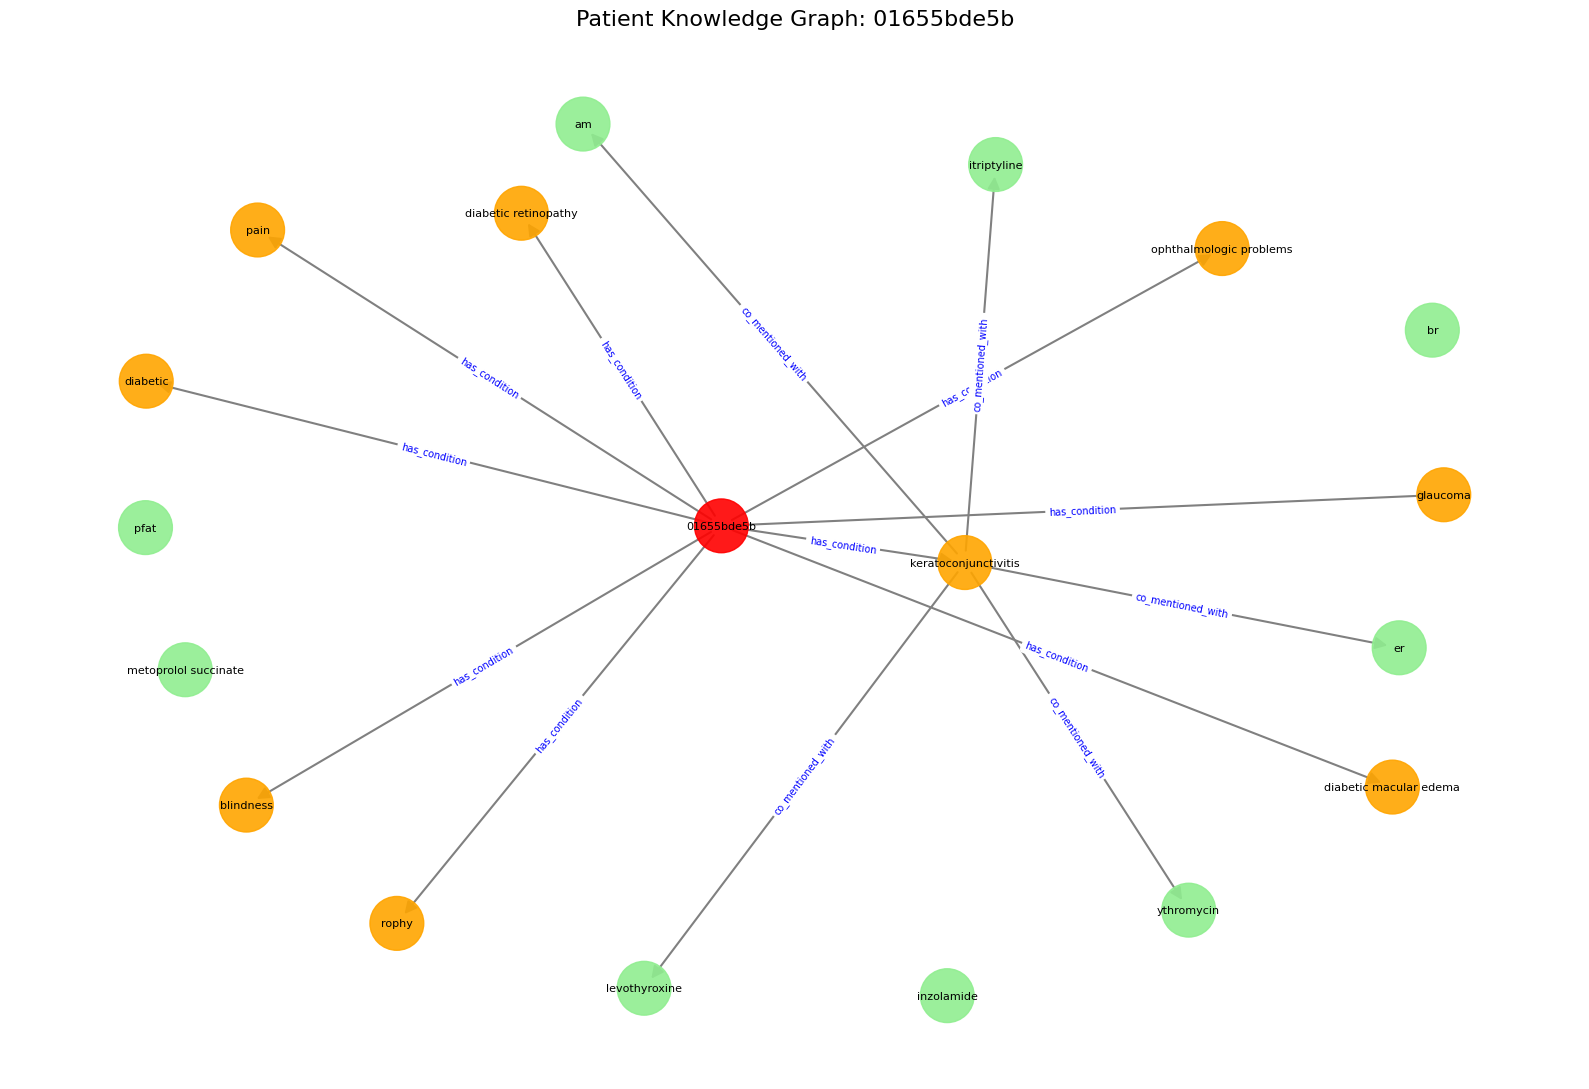


Processing 2/6: 01dcccc1a1.txt
Conditions: 14
Drugs: 5
Nodes: 20
Edges: 20


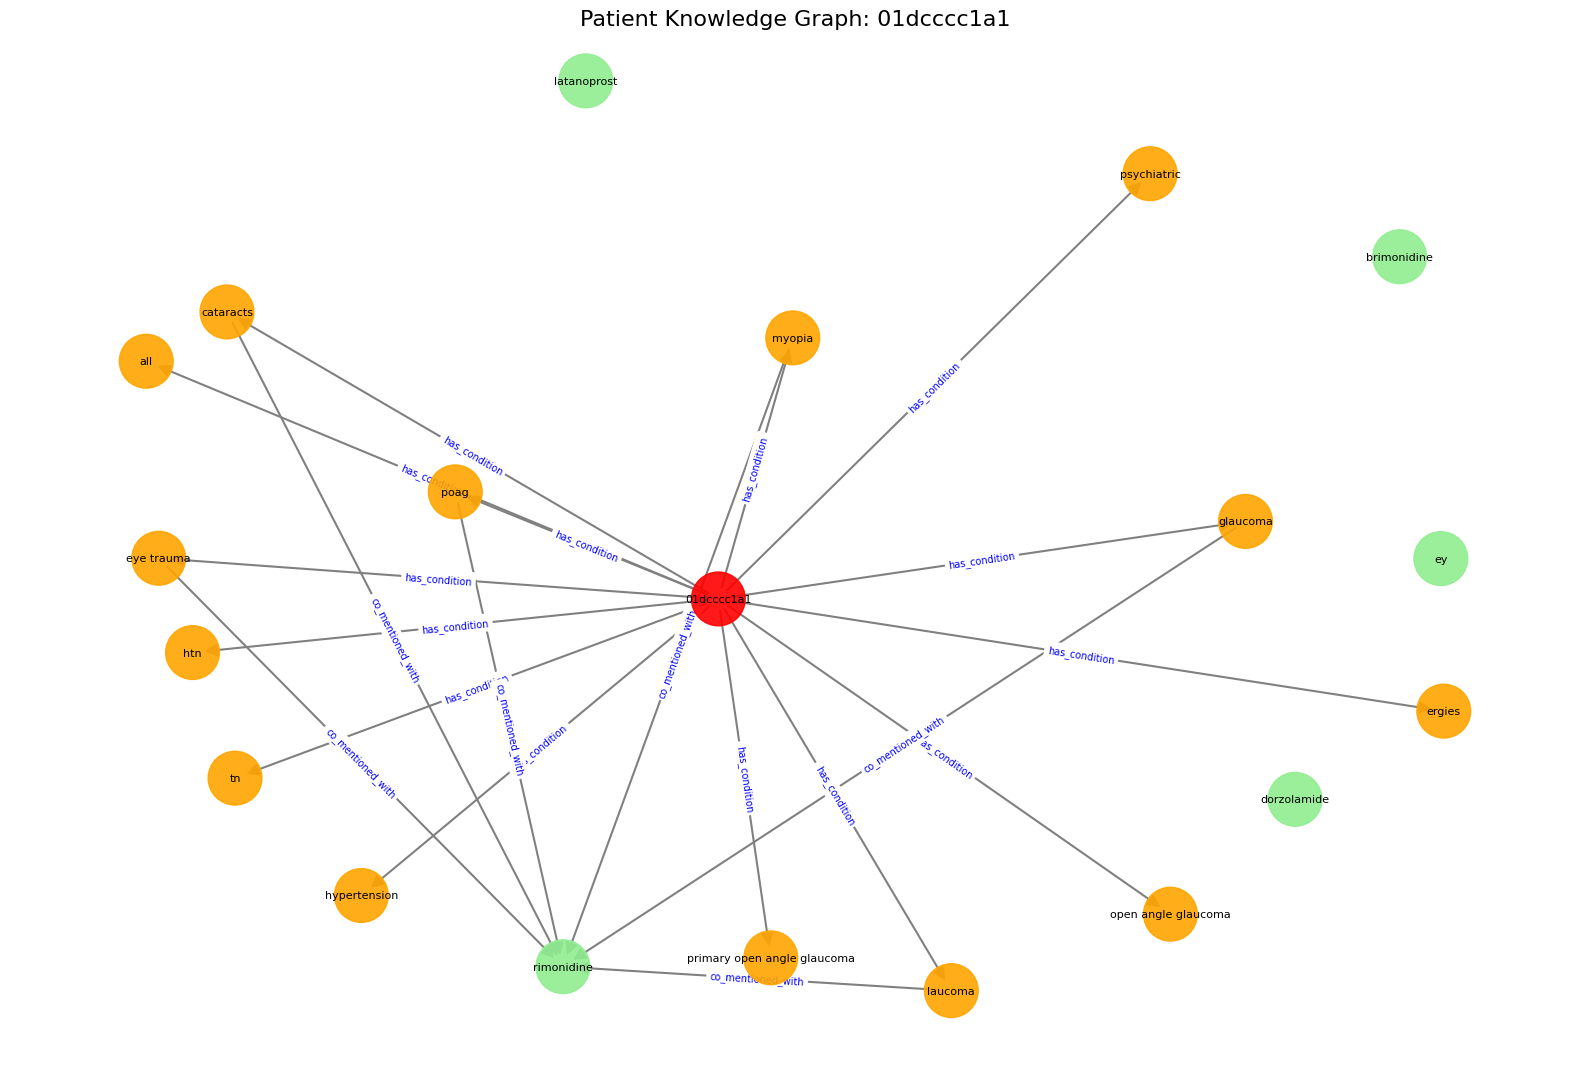


Processing 3/6: 0217483bd3.txt
Conditions: 34
Drugs: 25
Nodes: 60
Edges: 226


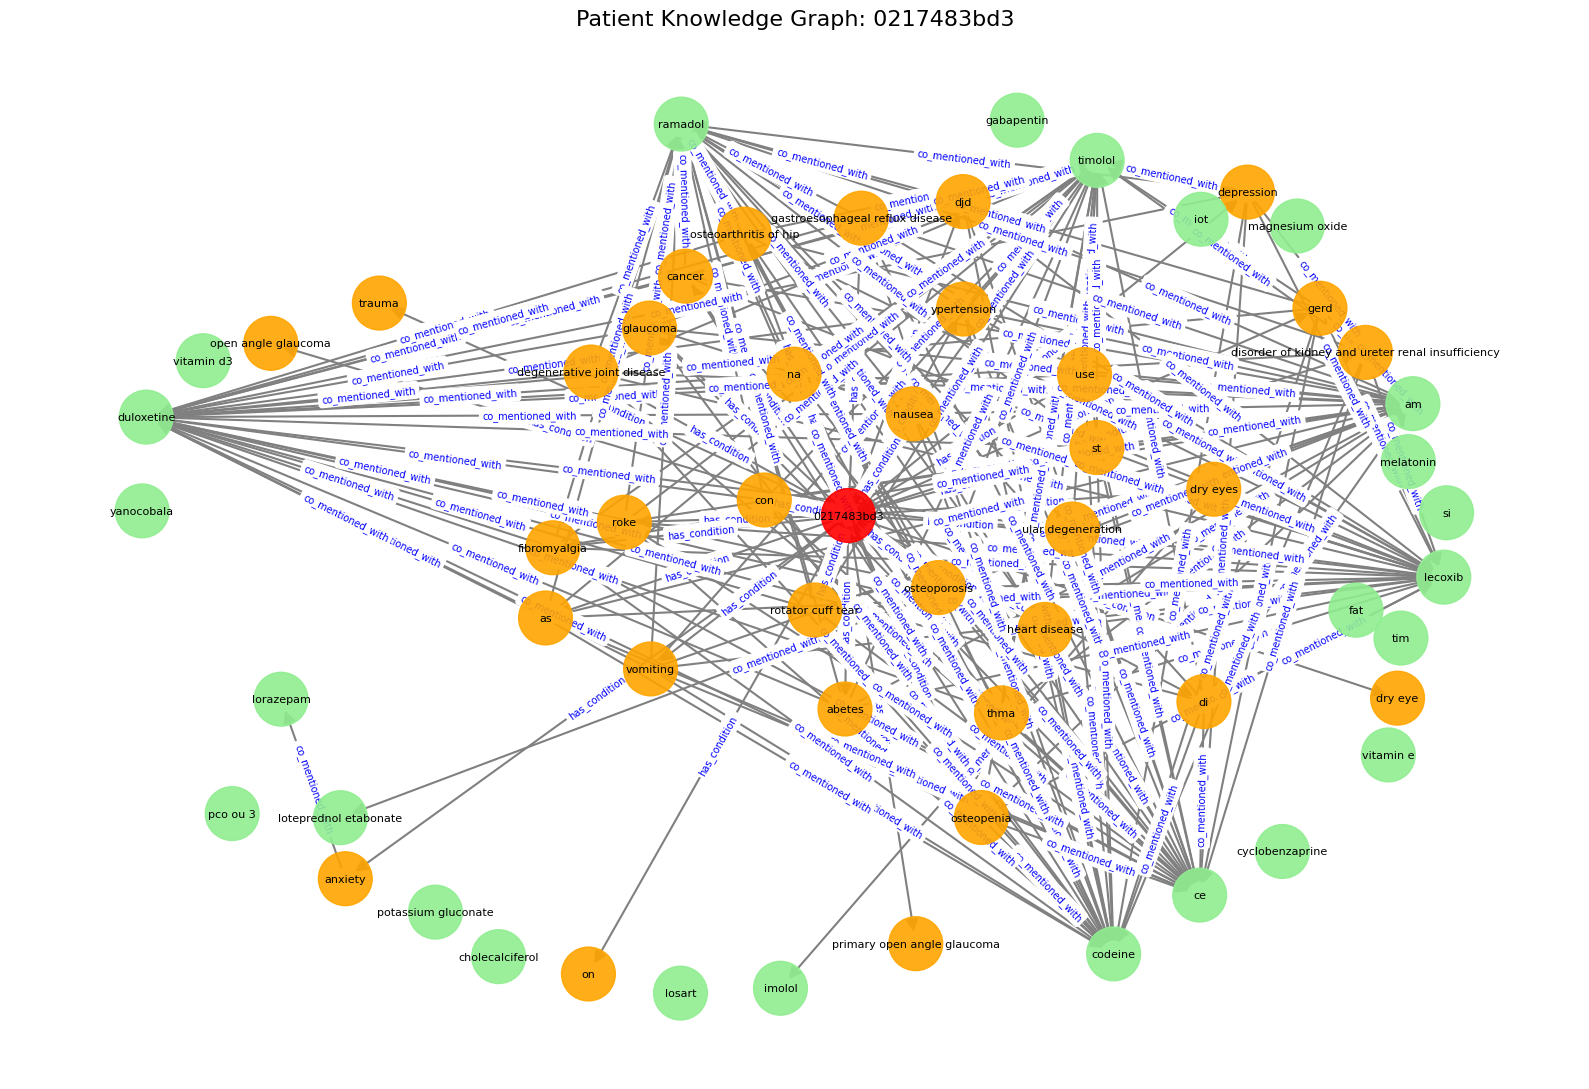


Processing 4/6: 025920c6c9.txt
Conditions: 17
Drugs: 14
Nodes: 32
Edges: 44


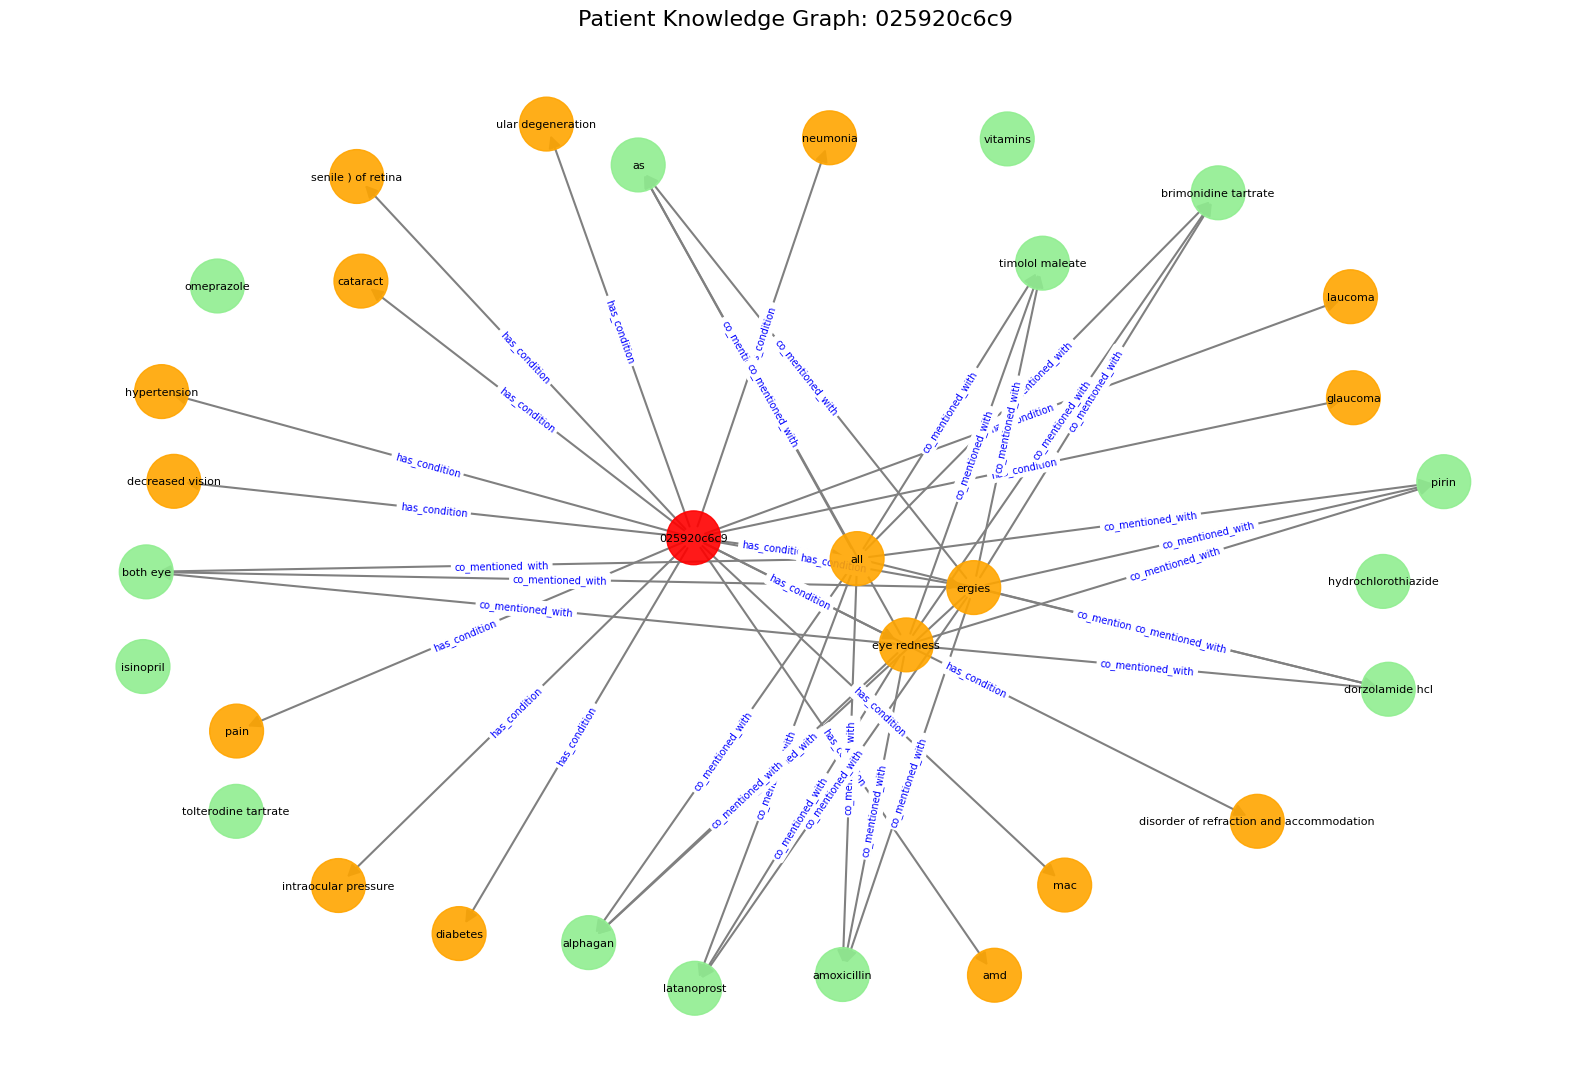


Processing 5/6: 0333bead9c.txt
Conditions: 18
Drugs: 11
Nodes: 30
Edges: 24


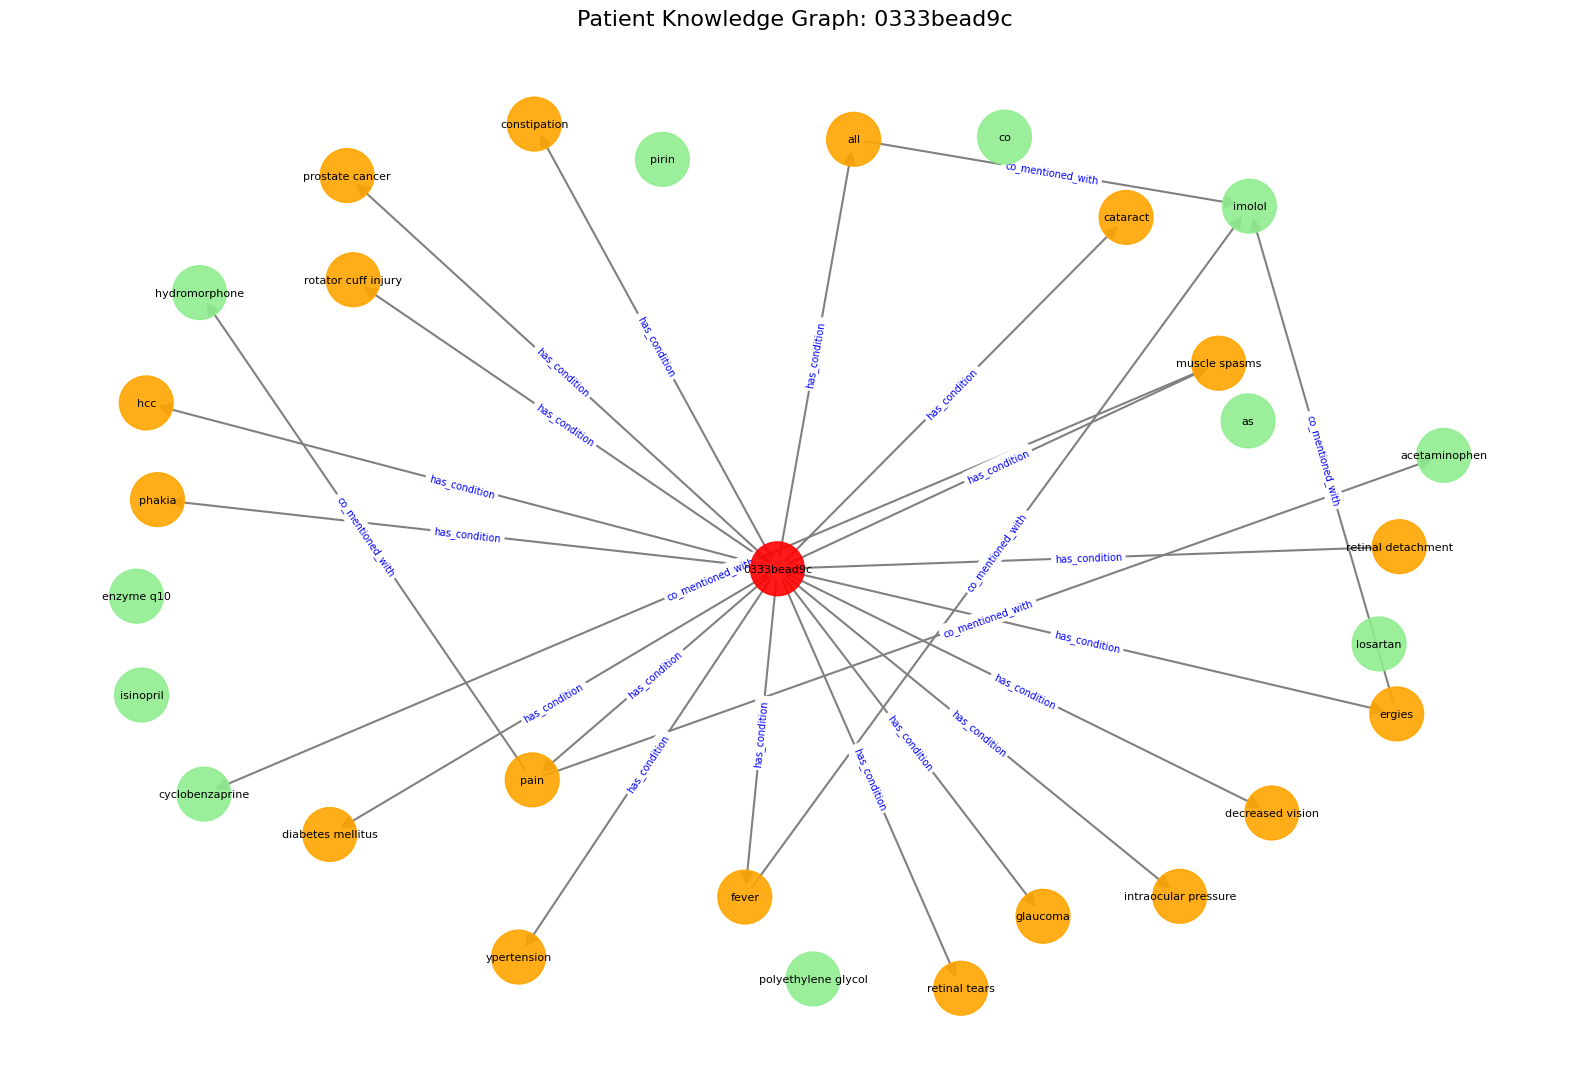


Processing 6/6: 04bd960ee3.txt
Conditions: 40
Drugs: 27
Nodes: 68
Edges: 222


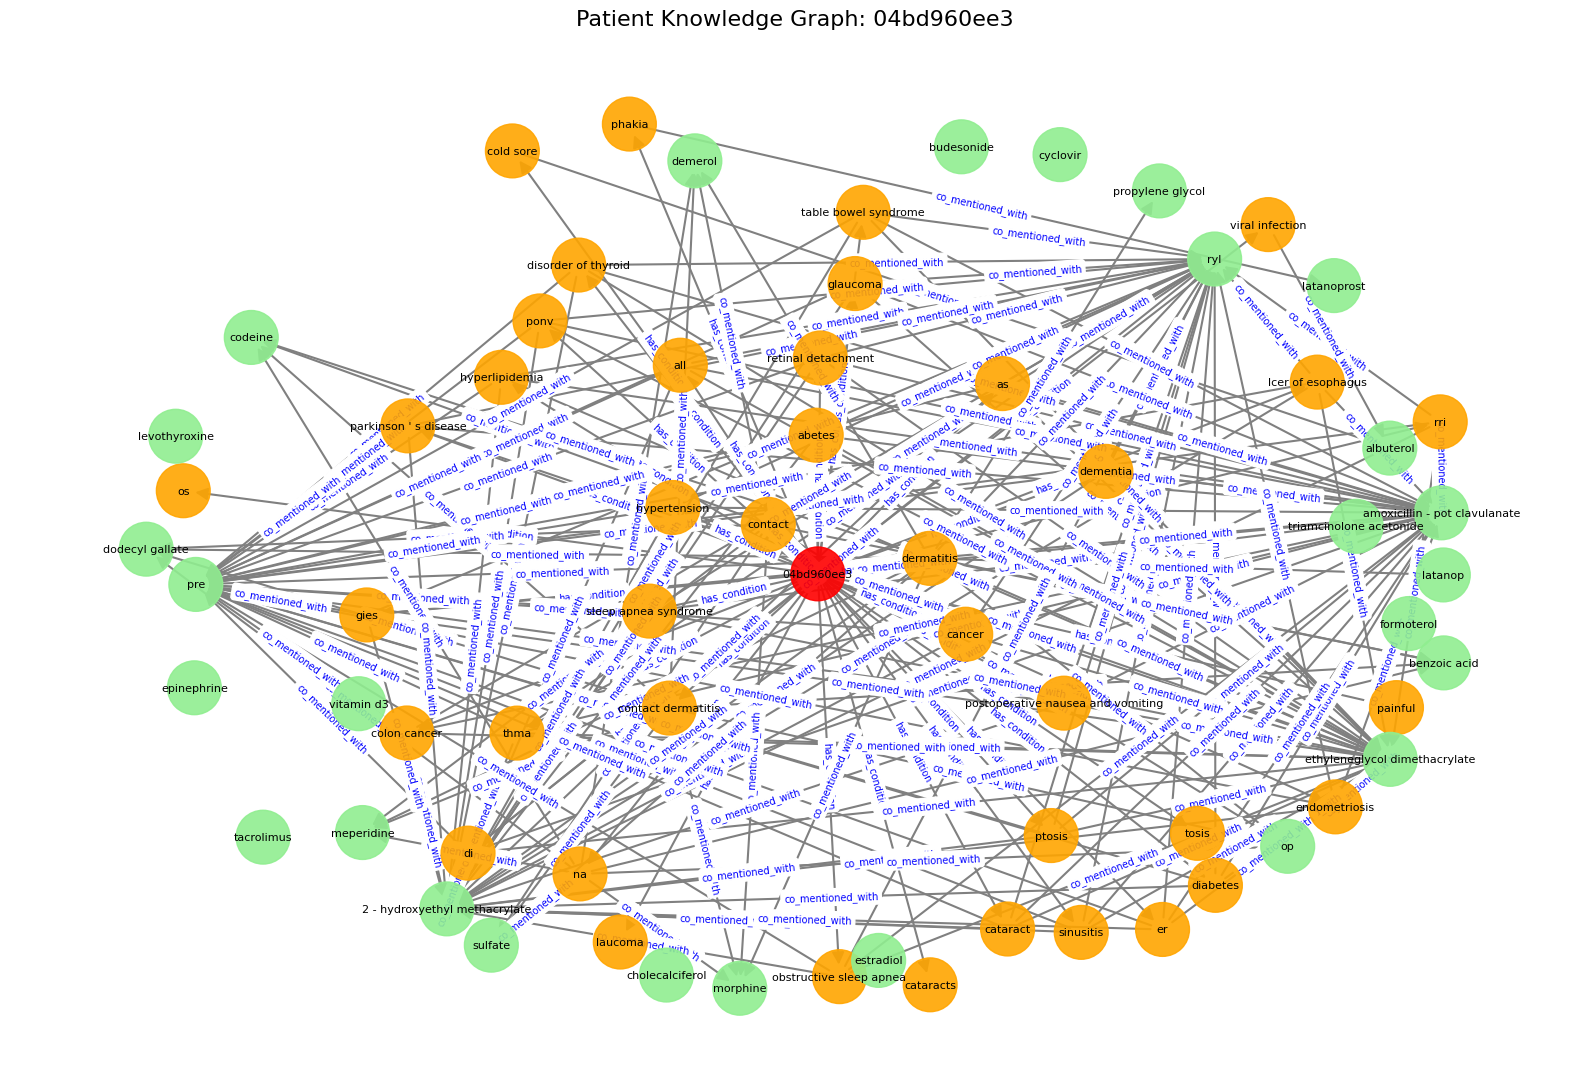


ALL PATIENT NOTES PROCESSED SUCCESSFULLY!
Total patients processed: 6


In [ ]:
combined_graph = nx.DiGraph()

all_patient_metrics = []

all_entity_records = []

all_relationship_records = []

for index, note_file in enumerate(
    selected_files,
    start=1
):

    patient_id = note_file.stem

    print("\n" + "=" * 70)

    print(
        f"Processing {index}/{len(selected_files)}: "
        f"{note_file.name}"
    )

    with open(
        note_file,
        "r",
        encoding="utf-8",
        errors="ignore"
    ) as file:

        note_text = file.read()

    # Build patient graph
    patient_graph, diseases, drugs = (
        build_patient_knowledge_graph(
            patient_id,
            note_text
        )
    )

    # Calculate patient metrics
    metrics = calculate_graph_metrics(
        patient_graph
    )

    print("Conditions:", len(diseases))
    print("Drugs:", len(drugs))

    print("Nodes:", metrics["Total Nodes"])

    print("Edges:", metrics["Total Edges"])

    # Save patient graph
    patient_graph_file = (
        OUTPUT_FOLDER
        / f"{patient_id}_graph.png"
    )

    draw_knowledge_graph(
        patient_graph,
        f"Patient Knowledge Graph: {patient_id}",
        patient_graph_file
    )

    # Patient metrics
    all_patient_metrics.append({
        "File": note_file.name,
        "Patient ID": patient_id,
        "Conditions Extracted": len(diseases),
        "Drugs Extracted": len(drugs),
        **metrics
    })

    # Entity records
    for disease in diseases:

        all_entity_records.append({
            "Patient ID": patient_id,
            "Entity": disease,
            "Entity Type": "Condition"
        })

    for drug in drugs:

        all_entity_records.append({
            "Patient ID": patient_id,
            "Entity": drug,
            "Entity Type": "Drug"
        })

    # Relationship records
    for source, target, data in (
        patient_graph.edges(data=True)
    ):

        all_relationship_records.append({
            "Patient ID": patient_id,
            "Source": source,
            "Target": target,
            "Relationship": data.get(
                "relation", ""
            ),
            "Evidence": data.get(
                "evidence", ""
            )
        })

    # Merge patient graphs
    combined_graph = nx.compose(
        combined_graph,
        patient_graph
    )

print("\n" + "=" * 70)

print("ALL PATIENT NOTES PROCESSED SUCCESSFULLY!")

print("Total patients processed:", len(selected_files))

In [ ]:
metrics_dataframe = pd.DataFrame(
    all_patient_metrics
)

display(metrics_dataframe)

metrics_dataframe.to_csv(
    OUTPUT_FOLDER / "patient_metrics.csv",
    index=False
)

print("Patient metrics saved!")

,File,Patient ID,Conditions Extracted,Drugs Extracted,Total Nodes,Total Edges,Average Degree,Density,Average Clustering Coefficient,Average Shortest Path Length,Weakly Connected Components
0,01655bde5b.txt,01655bde5b,9,9,19,14,1.4737,0.0819,0.0,2.2476,5
1,01dcccc1a1.txt,01dcccc1a1,14,5,20,20,2.0000,0.1053,0.0,1.9000,5
2,0217483bd3.txt,0217483bd3,34,25,60,226,7.5333,0.1277,0.0,1.9677,16
3,025920c6c9.txt,025920c6c9,17,14,32,44,2.7500,0.0887,0.0,2.2336,6
4,0333bead9c.txt,0333bead9c,18,11,30,24,1.6000,0.0552,0.0,2.2055,8
5,04bd960ee3.txt,04bd960ee3,40,27,68,222,6.5294,0.0975,0.0,2.2045,11


Patient metrics saved!


In [ ]:
entities_dataframe = pd.DataFrame(
    all_entity_records
)

display(
    entities_dataframe.head(30)
)

entities_dataframe.to_csv(
    OUTPUT_FOLDER / "extracted_entities.csv",
    index=False
)

print("Extracted entities saved!")

,Patient ID,Entity,Entity Type
0,01655bde5b,glaucoma,Condition
1,01655bde5b,rophy,Condition
2,01655bde5b,diabetic,Condition
3,01655bde5b,ophthalmologic problems,Condition
4,01655bde5b,pain,Condition
5,01655bde5b,diabetic macular edema,Condition
6,01655bde5b,blindness,Condition
7,01655bde5b,diabetic retinopathy,Condition
8,01655bde5b,keratoconjunctivitis,Condition
9,01655bde5b,ythromycin,Drug


Extracted entities saved!


In [ ]:
print("=" * 70)

print("COMBINED GLAUCOMA KNOWLEDGE GRAPH")

print("=" * 70)

combined_metrics = calculate_graph_metrics(
    combined_graph
)

for metric_name, metric_value in (
    combined_metrics.items()
):

    print(
        f"{metric_name}: {metric_value}"
    )

print("\nTotal Nodes:", combined_graph.number_of_nodes())

print("Total Edges:", combined_graph.number_of_edges())

pd.DataFrame([
    combined_metrics
]).to_csv(
    OUTPUT_FOLDER / "combined_graph_metrics.csv",
    index=False
)

COMBINED GLAUCOMA KNOWLEDGE GRAPH
Total Nodes: 183
Total Edges: 549
Average Degree: 6.0
Density: 0.033
Average Clustering Coefficient: 0.0
Average Shortest Path Length: 3.2754
Weakly Connected Components: 38

Total Nodes: 183
Total Edges: 549


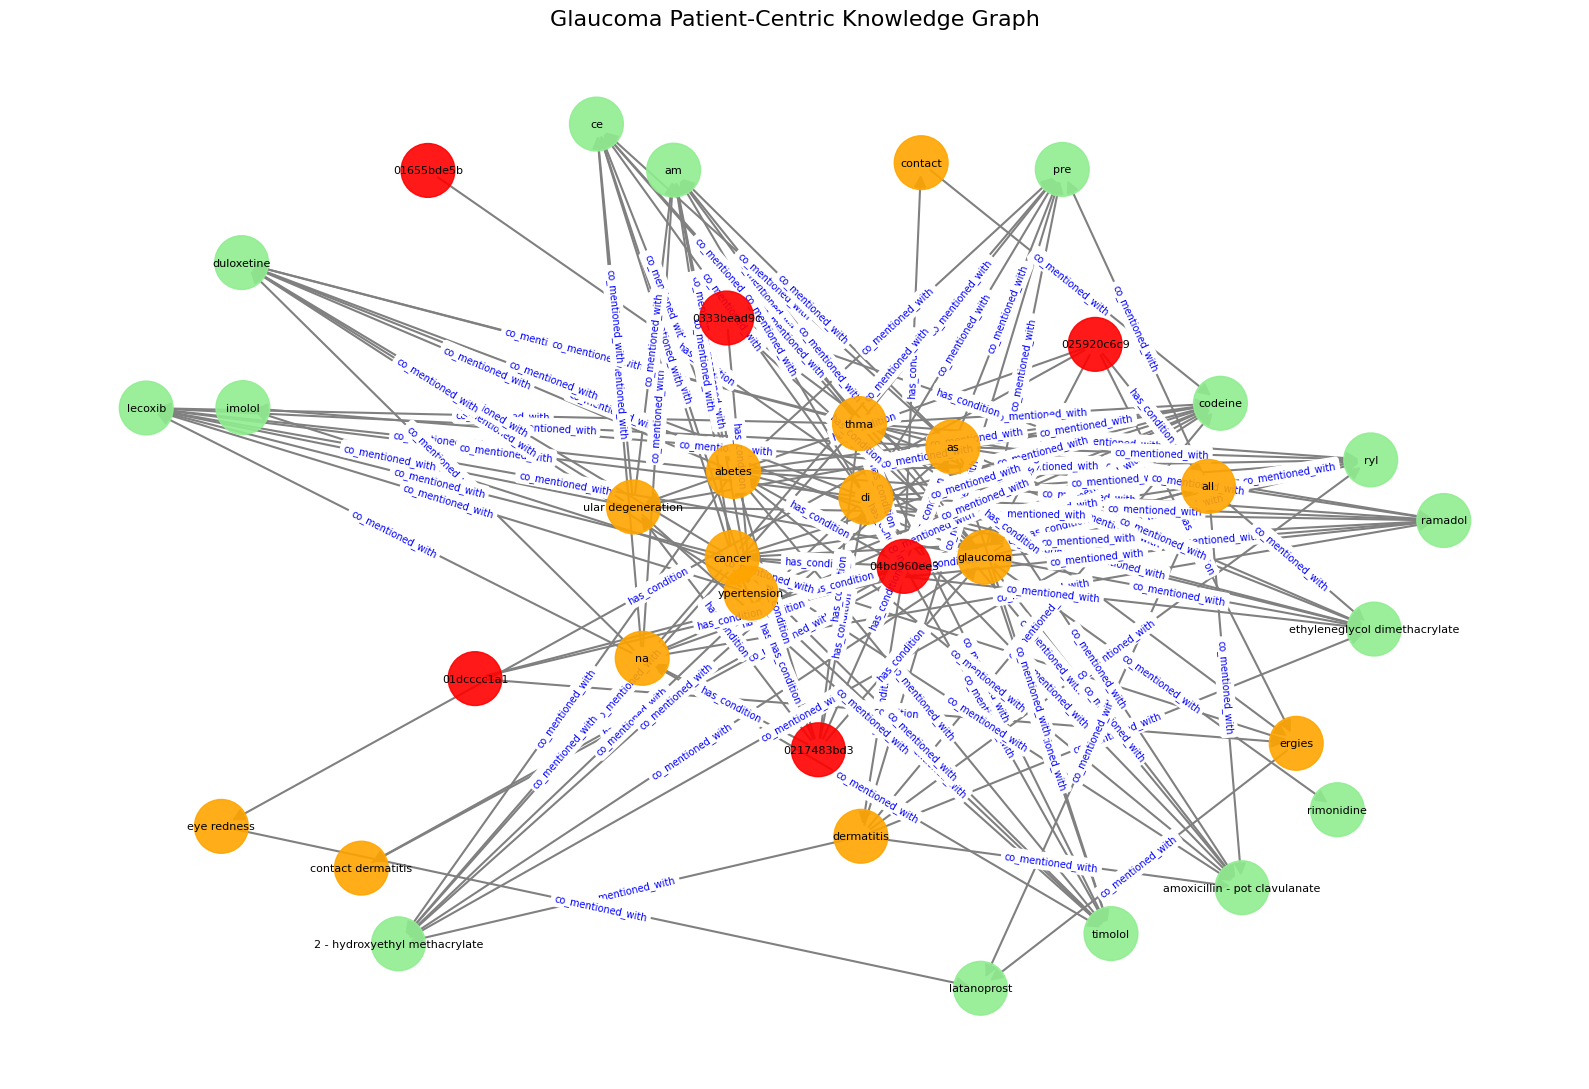

In [ ]:
def draw_neat_knowledge_graph(
    graph,
    title,
    save_path,
    max_patients=6,
    max_conditions=15,
    max_drugs=15
):

    patient_nodes = [
        n for n, d in graph.nodes(data=True)
        if d["node_type"] == "patient"
    ][:max_patients]

    condition_nodes = [
        n for n, d in graph.nodes(data=True)
        if d["node_type"] == "condition"
    ]

    drug_nodes = [
        n for n, d in graph.nodes(data=True)
        if d["node_type"] == "drug"
    ]

    condition_nodes = sorted(
        condition_nodes,
        key=lambda n: graph.degree(n),
        reverse=True
    )[:max_conditions]

    drug_nodes = sorted(
        drug_nodes,
        key=lambda n: graph.degree(n),
        reverse=True
    )[:max_drugs]

    selected_nodes = (
        patient_nodes
        + condition_nodes
        + drug_nodes
    )

    subgraph = graph.subgraph(
        selected_nodes
    ).copy()

    draw_knowledge_graph(
        subgraph,
        title,
        save_path
    )


combined_graph_file = (
    OUTPUT_FOLDER /
    "combined_neat_knowledge_graph.png"
)

draw_neat_knowledge_graph(
    graph=combined_graph,
    title="Glaucoma Patient-Centric Knowledge Graph",
    save_path=combined_graph_file,
    max_patients=6,
    max_conditions=15,
    max_drugs=15
)

In [ ]:
association_counter = Counter()

for source, target, data in combined_graph.edges(
    data=True
):

    relations = json.loads(
        data.get("relations_json", "{}")
    )

    evidence = relations.get(
        "treated_with", []
    )

    if evidence:

        condition = combined_graph.nodes[
            source
        ]["label"]

        drug = combined_graph.nodes[
            target
        ]["label"]

        association_counter[
            (condition, drug)
        ] += len(evidence)


if association_counter:

    rows = []

    for (condition, drug), count in (
        association_counter.items()
    ):

        rows.append({
            "Condition": condition,
            "Drug": drug,
            "Association Count": count
        })

    heatmap_dataframe = pd.DataFrame(rows)

    heatmap_data = heatmap_dataframe.pivot_table(
        index="Condition",
        columns="Drug",
        values="Association Count",
        aggfunc="sum",
        fill_value=0
    )

    plt.figure(
        figsize=(
            max(12, len(heatmap_data.columns) * 1.2),
            max(6, len(heatmap_data.index) * 0.7)
        )
    )

    sns.heatmap(
        heatmap_data,
        cmap="YlGnBu",
        annot=True,
        fmt="g",
        linewidths=0.5
    )

    plt.title(
        "Glaucoma Condition-Treatment Association Heatmap"
    )

    plt.xlabel("Medications")

    plt.ylabel("Conditions")

    plt.tight_layout()

    heatmap_file = (
        OUTPUT_FOLDER /
        "condition_treatment_heatmap.png"
    )

    plt.savefig(
        heatmap_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    heatmap_data.to_csv(
        OUTPUT_FOLDER / "condition_treatment_matrix.csv"
    )

else:

    print(
        "No explicit treatment-context associations found."
    )

No explicit treatment-context associations found.



Generating MAIN combined heatmap...


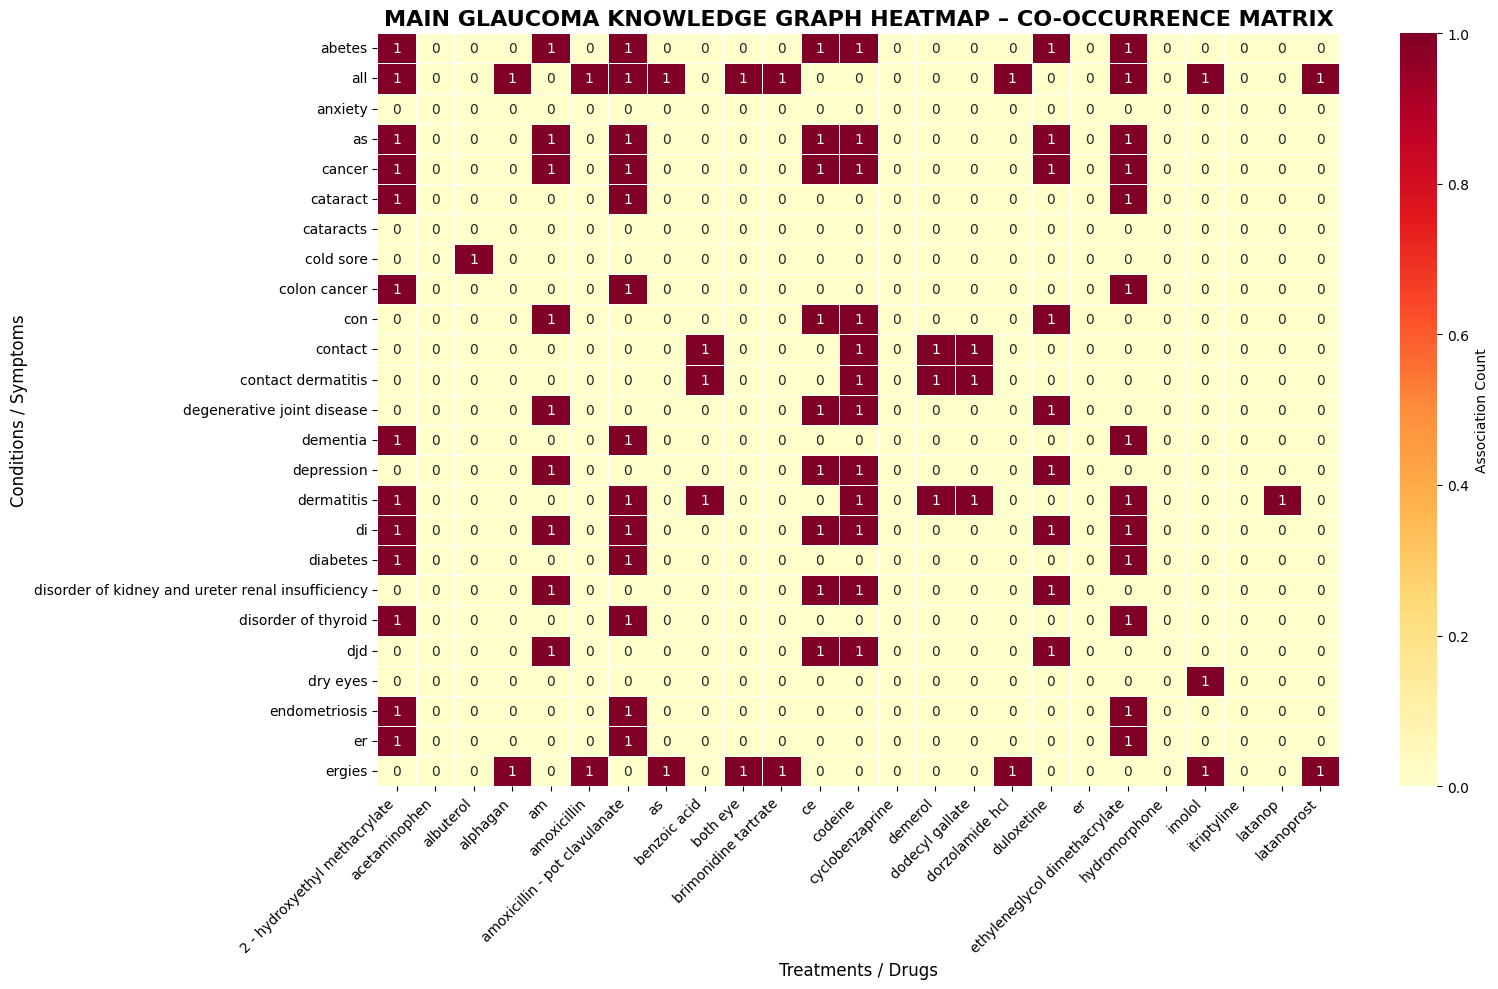

Main heatmap saved: /content/glaucoma_output/MAIN_COMBINED_HEATMAP.png


In [ ]:
# ============================================================
# MAIN COMBINED HEATMAP – ALL PATIENTS
# ============================================================

print("\nGenerating MAIN combined heatmap...")

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import json

main_heatmap_data = []

# Fallback to including co-mention relationships if treated_with isn't populated
for source, target, data in combined_graph.edges(data=True):
    relation_type = data.get("relation")
    if relation_type in ["treated_with", "co_mentioned_with"]:
        condition_label = combined_graph.nodes[source].get("label", source.replace("CONDITION::", ""))
        drug_label = combined_graph.nodes[target].get("label", target.replace("DRUG::", ""))

        relations = json.loads(data.get("relations_json", "{}"))
        evidence = relations.get("treated_with", []) or relations.get("co_mentioned_with", [])

        main_heatmap_data.append({
            "Condition": condition_label,
            "Treatment": drug_label,
            "Count": len(evidence) if evidence else 1
        })

if main_heatmap_data:
    heatmap_df = pd.DataFrame(main_heatmap_data)

    main_pivot = heatmap_df.pivot_table(
        index="Condition",
        columns="Treatment",
        values="Count",
        aggfunc="sum",
        fill_value=0
    )

    # Filter to show a cleaner map with only conditions/treatments that have some associations
    main_pivot = main_pivot.loc[(main_pivot.sum(axis=1) > 0), (main_pivot.sum(axis=0) > 0)]

    # Display top 20 conditions and treatments for readability if the matrix is huge
    main_pivot = main_pivot.iloc[:25, :25]

    plt.figure(figsize=(16, 10))

    sns.heatmap(
        main_pivot,
        annot=True,
        fmt="d",
        cmap="YlOrRd",
        linewidths=0.5,
        cbar_kws={"label": "Association Count"}
    )

    plt.title(
        "MAIN GLAUCOMA KNOWLEDGE GRAPH HEATMAP – CO-OCCURRENCE MATRIX",
        fontsize=16,
        fontweight="bold"
    )

    plt.xlabel("Treatments / Drugs", fontsize=12)
    plt.ylabel("Conditions / Symptoms", fontsize=12)
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()

    main_heatmap_path = OUTPUT_FOLDER / "MAIN_COMBINED_HEATMAP.png"
    plt.savefig(main_heatmap_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("Main heatmap saved:", main_heatmap_path)

else:
    print("No clinical associations found for the main heatmap.")

plt.show()

In [ ]:
relationships_dataframe = pd.DataFrame(
    all_relationship_records
)

relationships_file = (
    OUTPUT_FOLDER /
    "knowledge_graph_relationships.csv"
)

relationships_dataframe.to_csv(
    relationships_file,
    index=False
)

display(relationships_dataframe.head(20))

print("Relationships exported!")

,Patient ID,Source,Target,Relationship,Evidence
0,01655bde5b,PATIENT::01655bde5b,CONDITION::glaucoma,has_condition,
1,01655bde5b,PATIENT::01655bde5b,CONDITION::rophy,has_condition,
2,01655bde5b,PATIENT::01655bde5b,CONDITION::diabetic,has_condition,
3,01655bde5b,PATIENT::01655bde5b,CONDITION::ophthalmologic problems,has_condition,
4,01655bde5b,PATIENT::01655bde5b,CONDITION::pain,has_condition,
5,01655bde5b,PATIENT::01655bde5b,CONDITION::diabetic macular edema,has_condition,
6,01655bde5b,PATIENT::01655bde5b,CONDITION::blindness,has_condition,
7,01655bde5b,PATIENT::01655bde5b,CONDITION::diabetic retinopathy,has_condition,
8,01655bde5b,PATIENT::01655bde5b,CONDITION::keratoconjunctivitis,has_condition,
9,01655bde5b,CONDITION::keratoconjunctivitis,DRUG::ythromycin,co_mentioned_with,


Relationships exported!


In [ ]:
# Analyze the extracted graph metrics from metrics_dataframe
print("========== PATIENT METRICS SUMMARY ==========")
summary_metrics = metrics_dataframe[["Conditions Extracted", "Drugs Extracted", "Total Nodes", "Total Edges", "Average Degree", "Density"]].mean()
summary_df = pd.DataFrame(summary_metrics, columns=["Average Value"])
display(summary_df.round(4))

========== PATIENT METRICS SUMMARY ==========


,Average Value
Conditions Extracted,22.0000
Drugs Extracted,15.1667
Total Nodes,38.1667
Total Edges,91.6667
Average Degree,3.6477
Density,0.0927


### Model Evaluation
Let's evaluate our BioBERT Chemical NER model against the annotated ground-truth dataset. We'll compute token-level **Accuracy**, and exact-match entity-level **Precision, Recall, and F1-Score**.

In [ ]:
import os
import glob
import json
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# 1. Locate annotations
ANNOTATIONS_FOLDER = "/content/Glaucoma_Med_Dataset/Annotations"
jsonl_files = glob.glob(os.path.join(ANNOTATIONS_FOLDER, "**", "*.jsonl"), recursive=True)
if not jsonl_files:
    raise FileNotFoundError("No JSONL annotation file found in the Annotations folder!")

ANNOTATION_FILE = jsonl_files[0]
print("Using annotation file:", ANNOTATION_FILE)

# 2. Load ground-truth
records = []
with open(ANNOTATION_FILE, "r", encoding="utf-8") as file:
    for line in file:
        if not line.strip():
            continue
        # Clean up unquoted asterisks if present in patient metadata
        sanitized_line = re.sub(r":\s*\*+\b", ": null", line)
        sanitized_line = re.sub(r":\s*\*+\s*(,|})", r": null\1", sanitized_line)
        sanitized_line = re.sub(r'\\([^"\\/bfnrtu])', r'\1', sanitized_line)
        try:
            item = json.loads(sanitized_line)
        except Exception:
            continue

        text = item.get("text", "")
        labels = item.get("labels", [])
        if text:
            gold_drugs = set()
            for label in labels:
                if len(label) >= 3:
                    start, end, entity_type = label[:3]
                    if str(entity_type).upper() == "DRUG":
                        gold_drugs.add((int(start), int(end)))
            records.append({"text": text, "gold_drugs": gold_drugs})

print(f"Loaded {len(records)} annotated records for evaluation.")

# 3. Predict & evaluate
def predict_drug_spans(text):
    predictions = drug_ner(text)
    predicted_spans = set()
    for entity in predictions:
        start = entity.get("start")
        end = entity.get("end")
        if start is not None and end is not None:
            predicted_spans.add((int(start), int(end)))
    return predicted_spans

TP, FP, FN = 0, 0, 0
y_true_tokens, y_pred_tokens = [], []

# Evaluate a sample subset to run quickly, or run all if notebook is configured
eval_records = records[:100]  # Limiting to 100 sentences for quick execution demo
for index, record in enumerate(eval_records):
    text = record["text"]
    gold_spans = record["gold_drugs"]
    predicted_spans = predict_drug_spans(text)

    TP += len(gold_spans & predicted_spans)
    FP += len(predicted_spans - gold_spans)
    FN += len(gold_spans - predicted_spans)

    # Tokenize simply for token-level metrics
    tokens = list(re.finditer(r"\S+", text))
    for token in tokens:
        start_t, end_t = token.start(), token.end()
        gold_label = any(start_t < end and end_t > start for start, end in gold_spans)
        pred_label = any(start_t < end and end_t > start for start, end in predicted_spans)
        y_true_tokens.append(1 if gold_label else 0)
        y_pred_tokens.append(1 if pred_label else 0)

# Calculate final scores
precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0.0
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
accuracy = accuracy_score(y_true_tokens, y_pred_tokens) if y_true_tokens else 0.0

# Save & Display results
evaluation_df = pd.DataFrame({
    "Metric": ["Accuracy (Token-level)", "Precision (Exact Entity)", "Recall (Exact Entity)", "F1-Score (Exact Entity)"],
    "Score (%)": [accuracy * 100, precision * 100, recall * 100, f1 * 100]
})

print("\n========== MODEL PERFORMANCE METRICS (LIST) ==========")
print(f"1. Accuracy  : {accuracy * 100:.2f}%")
print(f"2. Precision : {precision * 100:.2f}%")
print(f"3. Recall    : {recall * 100:.2f}%")
print(f"4. F1-Score  : {f1 * 100:.2f}%")

display(evaluation_df.round(2))

evaluation_df.to_csv(OUTPUT_FOLDER / "model_evaluation_metrics.csv", index=False)

Using annotation file: /content/Glaucoma_Med_Dataset/Annotations/Combined_annotations.jsonl
Loaded 5520 annotated records for evaluation.

========== MODEL PERFORMANCE METRICS (LIST) ==========
1. Accuracy  : 95.84%
2. Precision : 46.88%
3. Recall    : 34.09%
4. F1-Score  : 39.47%


,Metric,Score (%)
0,Accuracy (Token-level),95.84
1,Precision (Exact Entity),46.88
2,Recall (Exact Entity),34.09
3,F1-Score (Exact Entity),39.47
